# Transport properties

Error bars are the STACIE uncertainty estimates. The Haven ratio is $\sigma_\mathrm{GK}/\sigma_\mathrm{NE}$.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

chapter = Path.cwd().resolve()
if chapter.name == 'notebooks': chapter = chapter.parent
sim = pd.read_csv(chapter / 'data' / 'transport_vs_temperature.csv')
d_plus = pd.read_csv(chapter / 'reference_data' / 'tokuda_diffusion_cation.csv')
d_minus = pd.read_csv(chapter / 'reference_data' / 'tokuda_diffusion_anion.csv')
conductivity = pd.read_csv(chapter / 'reference_data' / 'tokuda_conductivity.csv')
conductivity_ne = pd.read_csv(chapter / 'reference_data' / 'tokuda_conductivity_NE.csv')
# Exact density-chapter palette and display order.
colours = {'SO3LR': '#ed7d31', 'APPLE&P': '#0078b8', 'CL&P': '#009e73', 'CL&P-scaled': '#c83817'}
markers = {'APPLE&P': 'o', 'SO3LR': 'o', 'CL&P': 'o', 'CL&P-scaled': 'o'}
order = ['SO3LR', 'APPLE&P', 'CL&P', 'CL&P-scaled']  # data-drawing order
label_order = ['APPLE&P', 'CL&P-scaled', 'CL&P', 'SO3LR']
temps = [290, 300, 310, 320, 330]
plt.rcParams.update({'font.size': 14, 'font.family': 'sans-serif', 'axes.labelsize': 16, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'axes.linewidth': 1.5, 'lines.linewidth': 2.5, 'lines.markersize': 8})
figures = chapter / 'figures'; figures.mkdir(exist_ok=True)


/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)


/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


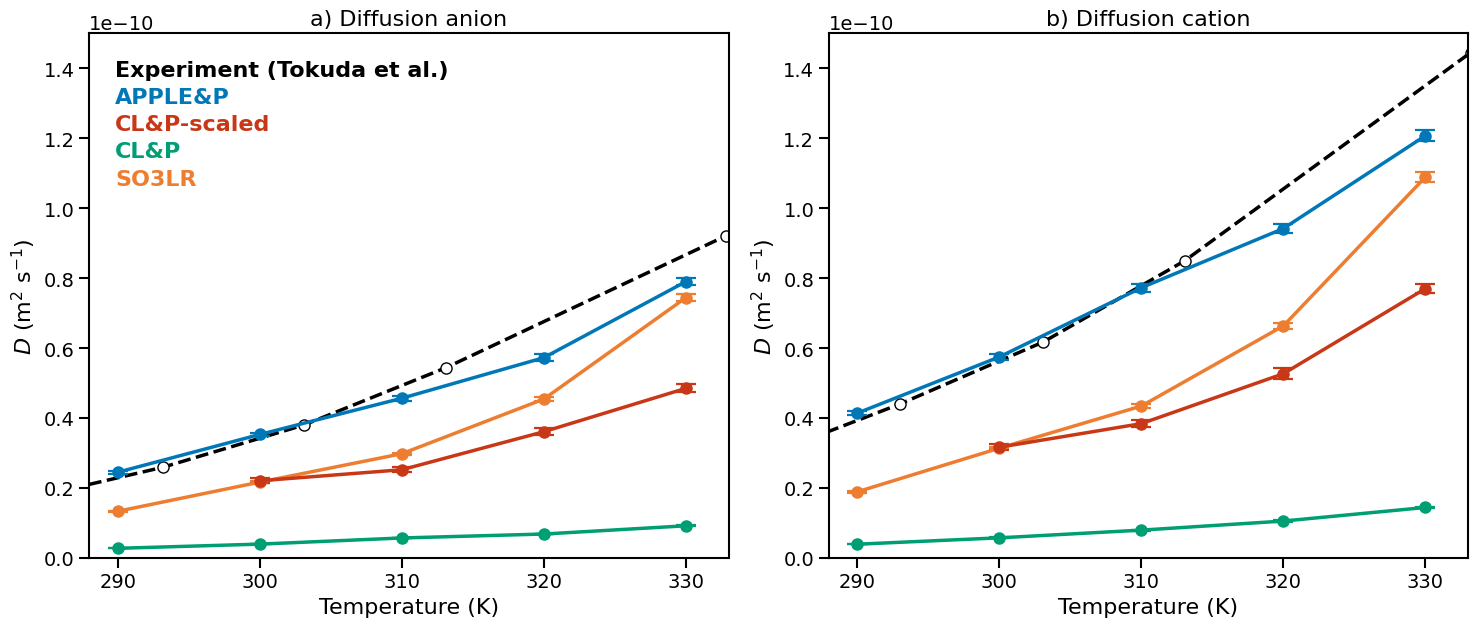

In [2]:
def style(ax, ylabel):
    ax.set(xlim=(288, 333), xticks=temps, xlabel='Temperature (K)', ylabel=ylabel)
    for spine in ax.spines.values(): spine.set_linewidth(1.5)
    ax.tick_params(width=1.5, length=7)

def direct_labels(ax, experiment=None):
    entries = []
    if experiment is not None: entries.append((experiment, 'black'))
    entries.extend((name, colours[name]) for name in label_order)
    for index, (text, color) in enumerate(entries):
        ax.text(.04, .95 - .052 * index, text, transform=ax.transAxes, color=color,
                fontsize=16, fontweight='bold', ha='left', va='top')

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
axes[0].set(ylim=(0, 1.5e-10))
axes[1].set(ylim=(0, 1.5e-10))
for ax, value, error, reference, title in [(axes[0], 'D_anion_m2_s', 'D_anion_std_m2_s', d_minus, 'a) Diffusion anion'), (axes[1], 'D_cation_m2_s', 'D_cation_std_m2_s', d_plus, 'b) Diffusion cation')]:
    ax.plot(reference.T_K, reference.D_m2_s, 'o--', color='black', mfc='white')
    for force_field in order:
        curve = sim[sim.force_field == force_field]
        ax.errorbar(curve.temperature_K, curve[value], yerr=curve[error], color=colours[force_field], marker=markers[force_field], capsize=7, capthick=1.6, elinewidth=1.6)
    style(ax, r'$D$ (m$^2$ s$^{-1}$)'); ax.set_title(title, fontsize=16)
direct_labels(axes[0], 'Experiment (Tokuda et al.)')
fig.tight_layout(); fig.savefig(figures / 'transport_summary_diffusion.png', dpi=300, bbox_inches='tight', facecolor='white')


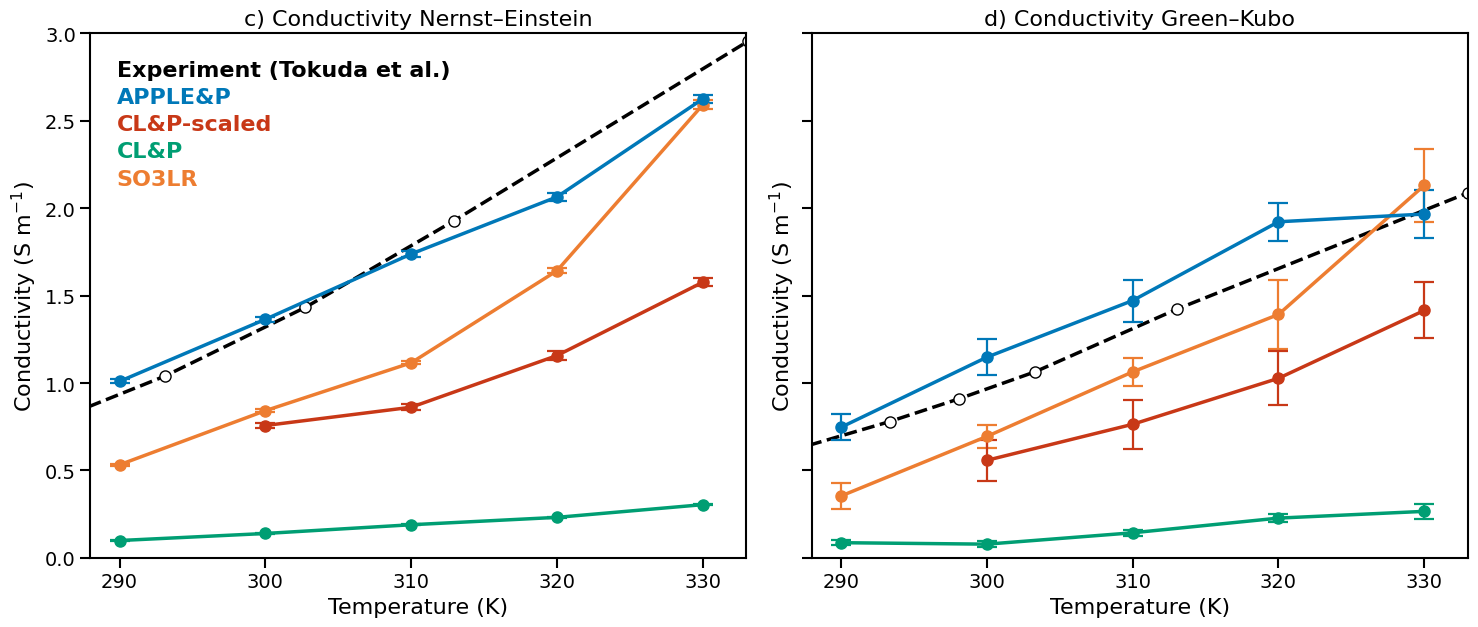

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
axes[0].plot(conductivity_ne.T_K, conductivity_ne.sigma_NE_S_per_m, 'o--', color='black', mfc='white')
axes[1].plot(conductivity.T_K, conductivity.sigma_S_per_m, 'o--', color='black', mfc='white')
for force_field in order:
    curve = sim[sim.force_field == force_field]
    axes[0].errorbar(curve.temperature_K, curve.sigma_NE_S_m, yerr=curve.sigma_NE_std_S_m, color=colours[force_field], marker=markers[force_field], capsize=7, capthick=1.6, elinewidth=1.6)
    axes[1].errorbar(curve.temperature_K, curve.sigma_GK_S_m, yerr=curve.sigma_GK_std_S_m, color=colours[force_field], marker=markers[force_field], capsize=7, capthick=1.6, elinewidth=1.6)
style(axes[0], r'Conductivity (S m$^{-1}$)'); axes[0].set_title('c) Conductivity Nernst–Einstein', fontsize=16)
style(axes[1], r'Conductivity (S m$^{-1}$)'); axes[1].set_title('d) Conductivity Green–Kubo', fontsize=16)
for ax in axes: ax.set_ylim(0, 3)
direct_labels(axes[0], 'Experiment (Tokuda et al.)')
fig.tight_layout(); fig.savefig(figures / 'transport_summary_conductivity.png', dpi=300, bbox_inches='tight', facecolor='white')


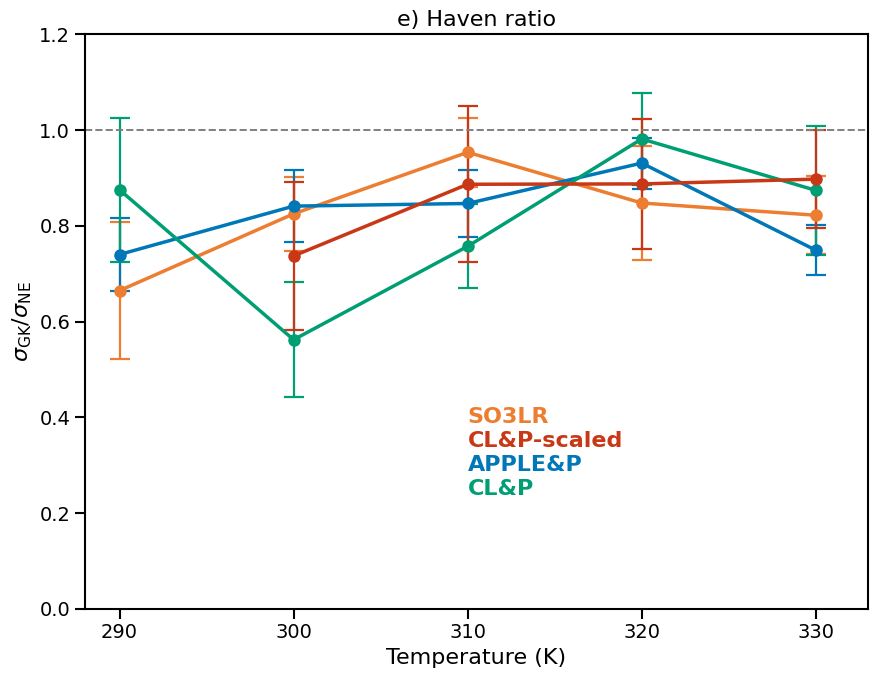

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
for force_field in order:
    curve = sim[sim.force_field == force_field]
    ax.errorbar(curve.temperature_K, curve.haven_ratio_GK_over_NE, yerr=curve.haven_ratio_std, color=colours[force_field], marker=markers[force_field], capsize=7, capthick=1.6, elinewidth=1.6)
ax.axhline(1, color='0.5', ls='--', lw=1.4)
style(ax, r'$\sigma_\mathrm{GK}/\sigma_\mathrm{NE}$'); ax.set_ylim(0, 1.2); ax.set_title('e) Haven ratio', fontsize=16)
haven_label_order = ['SO3LR', 'CL&P-scaled', 'APPLE&P', 'CL&P']
for label_y, force_field in zip((.40, .35, .30, .25), haven_label_order):
    ax.text(310, label_y, force_field, color=colours[force_field], fontsize=16,
            fontweight='bold', ha='left', va='center')
fig.tight_layout(); fig.savefig(figures / 'transport_summary_haven_ratio.png', dpi=300, bbox_inches='tight', facecolor='white')
